# Часть 1. Москва vs Санкт-Петербург: проверка гипотезы об активности пользователей

# Сравнение активности пользователей Яндекс Книг в Москве и Санкт-Петербурге

- Автор: Арсений Павлович
- Дата: 04.10.2026

## Цели и задачи проекта

**Цель:** проверить гипотезу о том, что пользователи Яндекс Книг из Санкт-Петербурга в среднем проводят больше времени за чтением и прослушиванием, чем пользователи из Москвы. Результат поможет понять, стоит ли учитывать город при планировании контента и маркетинга.

**Задачи:**
1. Загрузить данные об активности пользователей двух городов и проверить их качество: пропуски, дубликаты, пересечение пользователей между городами.
2. Сравнить группы: размеры выборок, средние, медианы, разброс и распределение часов активности.
3. Выбрать подходящий статистический тест и проверить одностороннюю гипотезу о различии средних.
4. Интерпретировать результат и подготовить аналитическую записку с выводами и возможными причинами.

## Описание данных

Файл `yandex_knigi_data.csv` подготовлен SQL-запросом к базе Яндекс Книг (период: 1 сентября – 11 декабря 2024 года). Каждая строка — один пользователь в одном городе:

- `city` — город пользователя (Москва или Санкт-Петербург);
- `puid` — идентификатор пользователя;
- `hours` — суммарное время чтения и прослушивания за период, в часах.

## Содержимое проекта

1. Загрузка и предобработка данных: удаление лишнего столбца, проверка пользователей, встречающихся в обоих городах
2. Сравнение групп: размеры, описательные статистики, распределения
3. Проверка гипотезы: односторонний t-тест Уэлча
4. Аналитическая записка: выводы и возможные причины

## 1. Загрузка и предобработка данных

In [1]:
# Импортируем библиотеки, которые будем использовать в проекте
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats as st

from statsmodels.stats.proportion import proportions_ztest, proportion_effectsize
from statsmodels.stats.power import NormalIndPower

In [2]:
# Загружаем данные об активности пользователей Москвы и Санкт-Петербурга
data = pd.read_csv('https://code.s3.yandex.net/datasets/yandex_knigi_data.csv')

# Смотрим первые строки и общую информацию о таблице
display(data.head())
data.info()

,Unnamed: 0,city,puid,hours
0,0,Москва,9668,26.167776
1,1,Москва,16598,82.111217
2,2,Москва,80401,4.656906
3,3,Москва,140205,1.840556
4,4,Москва,248755,151.326434


<class 'pandas.DataFrame'>
RangeIndex: 8784 entries, 0 to 8783
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   Unnamed: 0  8784 non-null   int64  
 1   city        8784 non-null   str    
 2   puid        8784 non-null   int64  
 3   hours       8784 non-null   float64
dtypes: float64(1), int64(2), str(1)
memory usage: 274.6 KB


In [3]:
# Удаляем лишний столбец со старым индексом
data = data.drop(columns='Unnamed: 0')

display(data.head())

,city,puid,hours
0,Москва,9668,26.167776
1,Москва,16598,82.111217
2,Москва,80401,4.656906
3,Москва,140205,1.840556
4,Москва,248755,151.326434


In [4]:
# Считаем строки пользователей, у которых puid встречается больше одного раза
dup_mask = data.duplicated(subset=['puid'], keep=False)
print('Строк с повторяющимся puid:', dup_mask.sum())
print('Уникальных таких пользователей:', data.loc[dup_mask, 'puid'].nunique())

Строк с повторяющимся puid: 488
Уникальных таких пользователей: 244


In [5]:
# Смотрим на строки таких пользователей; сортируем по puid, чтобы пары стояли рядом
data[dup_mask].sort_values('puid').head(10)

,city,puid,hours
35,Москва,2637041,10.317371
6247,Санкт-Петербург,2637041,3.883926
134,Москва,9979490,32.415573
6274,Санкт-Петербург,9979490,1.302997
145,Москва,10597984,42.931506
6279,Санкт-Петербург,10597984,9.041320
150,Москва,10815097,9.086655
6283,Санкт-Петербург,10815097,0.323291
187,Москва,13626259,21.104167
6300,Санкт-Петербург,13626259,1.648434


244 пользователя встречаются в обоих городах (488 строк, около 5.6% данных). Отнести их к одному городу однозначно нельзя, а присутствие одного человека в обеих группах нарушает независимость выборок, необходимую для t-теста. Поэтому удаляем таких пользователей полностью.

In [6]:
# Удаляем пользователей, которые встречаются в обоих городах:
# оставляем только строки, у которых нет двойника по puid
data = data[~dup_mask].reset_index(drop=True)
print(data.shape)

(8296, 3)


## 2. Сравнение групп

In [7]:
# Считаем размеры групп: сколько пользователей в Москве и Петербурге
print(data['city'].value_counts())

# И их доли от общего числа пользователей
print(data['city'].value_counts(normalize=True).round(3))

city
Москва             5990
Санкт-Петербург    2306
Name: count, dtype: int64
city
Москва             0.722
Санкт-Петербург    0.278
Name: proportion, dtype: float64


In [8]:
# Статистики по городам
data.groupby('city')['hours'].describe()

,count,mean,std,min,25%,50%,75%,max
city,,,,,,,,
Москва,5990.0,10.848192,36.925622,0.000022,0.057042,0.888232,5.933439,857.209373
Санкт-Петербург,2306.0,11.264433,39.831755,0.000025,0.060173,0.875355,6.138424,978.764775


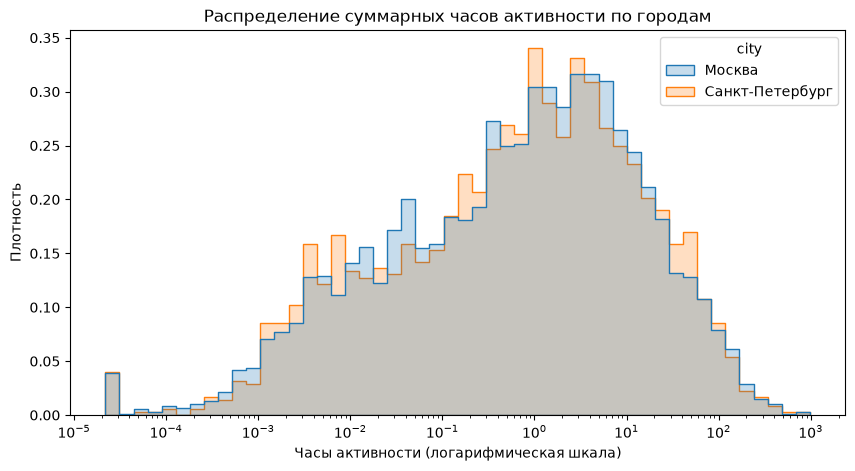

In [9]:
# Строим распределение часов активности по городам.
# Логарифмическая шкала: распределение сильно скошено вправо,
# density + common_norm=False: группы разного размера, сравниваем форму, а не высоту
plt.figure(figsize=(10, 5))
sns.histplot(data=data, x='hours', hue='city', stat='density',
             common_norm=False, log_scale=True, bins=50, element='step')
plt.title('Распределение суммарных часов активности по городам')
plt.xlabel('Часы активности (логарифмическая шкала)')
plt.ylabel('Плотность')
plt.show()

**Промежуточный вывод:**
- Группы неравные: 5990 пользователей в Москве и 2306 в Санкт-Петербурге (72% и 28%).
- Средняя активность почти одинакова: 10.85 ч в Москве и 11.26 ч в Санкт-Петербурге; медианы совпадают (около 0.9 ч).
- Распределение часов сильно скошено вправо: половина пользователей провела в приложении меньше часа за весь период, при этом встречаются значения до 850–980 часов. Среднее в 12 раз больше медианы и чувствительно к таким выбросам.
- На логарифмической шкале формы распределений в двух городах практически совпадают.
- Группы различаются по размеру, а стандартные отклонения у них разные (36.9 и 39.8), поэтому для проверки гипотезы выбран t-тест Уэлча: он не требует равенства дисперсий. Выборки большие, поэтому по ЦПТ распределение средних близко к нормальному, и t-тест применим, несмотря на скошенность данных.

## 3. Проверка гипотезы

- Нулевая гипотеза H₀: среднее время активности пользователей в Санкт-Петербурге не больше, чем в Москве.
- Альтернативная гипотеза H₁: среднее время активности пользователей в Санкт-Петербурге больше, чем в Москве.

In [10]:
# Формируем выборки часов активности для каждого города
moscow = data.loc[data['city'] == 'Москва', 'hours']
spb = data.loc[data['city'] == 'Санкт-Петербург', 'hours']

# Уровень статистической значимости
alpha = 0.05

# Односторонний t-тест Уэлча:
# H0: среднее СПб <= среднее Москвы; H1: среднее СПб > среднее Москвы
results = st.ttest_ind(spb, moscow, equal_var=False, alternative='greater')

print(f'p-value: {results.pvalue:.4f}')

if results.pvalue < alpha:
    print('Отвергаем нулевую гипотезу: пользователи из СПб в среднем активнее москвичей')
else:
    print('Нет оснований отвергнуть нулевую гипотезу: значимой разницы в пользу СПб не найдено')

p-value: 0.3318
Нет оснований отвергнуть нулевую гипотезу: значимой разницы в пользу СПб не найдено


## 4. Аналитическая записка

**Тест и уровень значимости.** Для сравнения средней активности использован односторонний t-тест Уэлча для двух независимых выборок (`scipy.stats.ttest_ind`, `equal_var=False`, `alternative='greater'`). Выбор обусловлен разным размером групп и неравными дисперсиями. Уровень значимости α = 0.05. Перед тестом удалены 244 пользователя, встречавшиеся в обоих городах, чтобы выборки были независимыми.

**Результат.** p-value = 0.33.

**Интерпретация.** p-value значительно больше α, поэтому нет оснований отвергнуть нулевую гипотезу. Статистически значимых данных о том, что пользователи из Санкт-Петербурга в среднем проводят в приложении больше времени, чем москвичи, не получено. Наблюдаемая разница средних (около 0.4 ч, ~4%) мала по сравнению с разбросом данных (стандартное отклонение около 37–40 ч) и вероятнее всего объясняется случайностью; медианы в двух городах практически совпадают.

**Возможные причины:**
1. Аудитории двух городов похожи: это жители крупнейших городов с одним и тем же каталогом, ценой подписки и схожим образом жизни (длительные поездки в транспорте, близкие доходы), поэтому и сценарии использования сервиса похожи.
2. Активность сильно зависит от небольшой доли очень активных пользователей (до 850–980 часов за период). Такие выбросы создают большой разброс, на фоне которого небольшая разница средних не может быть статистически значимой.

**Рекомендация.** Город не стоит рассматривать как фактор, влияющий на активность: для сегментации полезнее изучать другие признаки — тип контента (книги или аудиокниги), платформу, вовлечённость пользователя.

----

# Часть 2. Анализ результатов A/B-тестирования

## 1. Цели исследования

**Цель:** оценить корректность проведения A/B-теста `interface_eu_test` и проверить гипотезу о том, что упрощённый интерфейс сайта BitMotion Kit повышает конверсию зарегистрированных пользователей в покупателей в течение 7 дней после регистрации как минимум на 3 процентных пункта.

**Задачи:**
1. Проверить данные на целостность: типы, пропуски, дубликаты.
2. Проверить корректность теста: состав участников, равномерность групп, пересечения с конкурирующим тестом.
3. Ограничить события горизонтом 7 дней с момента регистрации и оценить достаточность выборки.
4. Сравнить конверсию в покупку в группах A и B статистическим тестом и сделать вывод о внедрении нового интерфейса.

## 2. Загрузка и проверка данных

In [11]:
# Загружаем данные об участниках тестов и о событиях пользователей
participants = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_participants.csv')
events = pd.read_csv('https://code.s3.yandex.net/datasets/ab_test_events.zip',
                     parse_dates=['event_dt'], low_memory=False)

In [12]:
# Знакомимся с таблицей участников
display(participants.head())
participants.info()

# Какие тесты есть в данных и сколько в них участников по группам
print(participants.groupby(['ab_test', 'group'])['user_id'].nunique())

# Полные дубликаты строк
print('Дубликатов в participants:', participants.duplicated().sum())

,user_id,group,ab_test,device
0,0002CE61FF2C4011,B,interface_eu_test,Mac
1,001064FEAAB631A1,B,recommender_system_test,Android
2,001064FEAAB631A1,A,interface_eu_test,Android
3,0010A1C096941592,A,recommender_system_test,Android
4,001E72F50D1C48FA,A,interface_eu_test,Mac


<class 'pandas.DataFrame'>
RangeIndex: 14525 entries, 0 to 14524
Data columns (total 4 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   user_id  14525 non-null  str  
 1   group    14525 non-null  str  
 2   ab_test  14525 non-null  str  
 3   device   14525 non-null  str  
dtypes: str(4)
memory usage: 454.0 KB
ab_test                  group
interface_eu_test        A        5383
                         B        5467
recommender_system_test  A        2747
                         B         928
Name: user_id, dtype: int64
Дубликатов в participants: 0


In [13]:
# Знакомимся с таблицей событий
display(events.head())
events.info()

# Типы событий и их количество
print(events['event_name'].value_counts())

# Полные дубликаты строк и диапазон дат
print('Дубликатов в events:', events.duplicated().sum())
print('Период событий:', events['event_dt'].min(), '—', events['event_dt'].max())

,user_id,event_dt,event_name,details
0,GLOBAL,2020-12-01 00:00:00,End of Black Friday Ads Campaign,ZONE_CODE15
1,CCBE9E7E99F94A08,2020-12-01 00:00:11,registration,0.0
2,GLOBAL,2020-12-01 00:00:25,product_page,NaN
3,CCBE9E7E99F94A08,2020-12-01 00:00:33,login,NaN
4,CCBE9E7E99F94A08,2020-12-01 00:00:52,product_page,NaN


<class 'pandas.DataFrame'>
RangeIndex: 787286 entries, 0 to 787285
Data columns (total 4 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   user_id     787286 non-null  str           
 1   event_dt    787286 non-null  datetime64[us]
 2   event_name  787286 non-null  str           
 3   details     249022 non-null  str           
dtypes: datetime64[us](1), str(3)
memory usage: 24.0 MB
event_name
login                                 248285
product_page                          195606
registration                          144183
purchase                              104836
product_cart                           94373
End of Black Friday Ads Campaign           1
Start of Christmas&New Year Promo          1
Start of CIS New Year Gift Lottery         1
Name: count, dtype: int64
Дубликатов в events: 36318
Период событий: 2020-12-01 00:00:00 — 2020-12-31 23:59:48


**Промежуточный вывод о целостности данных:**
- `participants`: 14 525 строк, пропусков и полных дубликатов нет. В данных два теста: изучаемый `interface_eu_test` и конкурирующий `recommender_system_test`.
- `events`: 787 286 строк за период с 1 по 31 декабря 2020 года, дата события приведена к типу datetime. Пропуски есть только в столбце `details` — он заполняется лишь для части событий (например, сумма покупки) и для расчёта конверсии не нужен.
- В `events` найдено 36 318 полных дубликатов и служебные записи с `user_id = 'GLOBAL'` (маркетинговые события, не связанные с пользователями) — их удалим перед анализом.
- Для анализа есть все нужные события: `registration` (точка отсчёта для горизонта 7 дней) и `purchase` (покупка).

## 3. Корректность проведения теста

### 3.1. Участники теста: соответствие ТЗ, распределение по группам, пересечения с конкурирующим тестом

In [14]:
# Оставляем участников изучаемого теста
eu_test = participants[participants['ab_test'] == 'interface_eu_test']

# Проверяем, нет ли пользователей, попавших сразу в обе группы нашего теста
groups_per_user = eu_test.groupby('user_id')['group'].nunique()
print('Пользователей сразу в группах A и B:', (groups_per_user > 1).sum())

# Проверяем равномерность распределения по группам
group_sizes = eu_test.groupby('group')['user_id'].nunique()
print(group_sizes)
print(f'Относительная разница размеров групп: {(group_sizes.max() - group_sizes.min()) / group_sizes.max():.2%}')

# Ищем пересечения с конкурирующим тестом recommender_system_test
rec_test = participants[participants['ab_test'] == 'recommender_system_test']
overlap = eu_test[eu_test['user_id'].isin(rec_test['user_id'])]
print('Участников нашего теста, которые есть и в конкурирующем:', overlap['user_id'].nunique())

# В какие группы конкурирующего теста они попали
print(rec_test[rec_test['user_id'].isin(eu_test['user_id'])]
      .groupby('group')['user_id'].nunique())

Пользователей сразу в группах A и B: 0
group
A    5383
B    5467
Name: user_id, dtype: int64
Относительная разница размеров групп: 1.54%
Участников нашего теста, которые есть и в конкурирующем: 887
group
A    665
B    222
Name: user_id, dtype: int64


In [15]:
# Удаляем всех участников изучаемого теста, которые одновременно участвуют в конкурирующем тесте:
# их поведение могло зависеть от обоих экспериментов, и эффект нового интерфейса нельзя отделить
overlap_users = eu_test.loc[eu_test['user_id'].isin(rec_test['user_id']), 'user_id'].unique()
eu_test = eu_test[~eu_test['user_id'].isin(overlap_users)]
print('Исключено пользователей, участвующих в обоих тестах:', len(overlap_users))

# Проверяем размеры групп после очистки
group_sizes = eu_test.groupby('group')['user_id'].nunique()
print(group_sizes)
print(f'Относительная разница размеров групп: {(group_sizes.max() - group_sizes.min()) / group_sizes.max():.2%}')

Исключено пользователей, участвующих в обоих тестах: 887
group
A    4952
B    5011
Name: user_id, dtype: int64
Относительная разница размеров групп: 1.18%


**Промежуточный вывод о корректности теста:**
- Название теста (`interface_eu_test`) и группы (A — контрольная, B — новый интерфейс) соответствуют техническому заданию.
- Ни один пользователь не попал одновременно в обе группы изучаемого теста.
- 887 участников изучаемого теста участвовали и в конкурирующем `recommender_system_test` (665 — в его группе A, 222 — в группе B). Их поведение могло зависеть от обоих экспериментов, и эффект нового интерфейса для них нельзя отделить, поэтому исключаем всех 887 пользователей.
- После очистки в группах 4952 (A) и 5011 (B) пользователей, разница 1.18% — распределение равномерное.

### 3.2. События участников теста

In [16]:
# Удаляем полные дубликаты событий и служебные записи GLOBAL (маркетинговые события, не пользователи)
events = events.drop_duplicates()
events = events[events['user_id'] != 'GLOBAL']

# Оставляем только события участников изучаемого теста и добавляем их группу
test_events = events.merge(eu_test[['user_id', 'group']], on='user_id', how='inner')
print('Событий участников теста:', len(test_events))
print('Участников, у которых есть события:', test_events['user_id'].nunique())

Событий участников теста: 68074
Участников, у которых есть события: 9963


### 3.3. Горизонт анализа: 7 дней после регистрации

In [17]:
# Дата регистрации каждого участника — его первое событие registration
reg = (test_events[test_events['event_name'] == 'registration']
       .groupby('user_id')['event_dt'].min()
       .rename('reg_dt'))
print('Участников без события регистрации:', test_events['user_id'].nunique() - len(reg))

# Добавляем дату регистрации к событиям и считаем лайфтайм — время с момента регистрации
test_events = test_events.merge(reg, on='user_id', how='inner')
test_events['lifetime'] = test_events['event_dt'] - test_events['reg_dt']

# Оставляем события, совершённые в течение первых 7 дней после регистрации
test_events_7d = test_events[(test_events['lifetime'] >= pd.Timedelta(0)) &
                             (test_events['lifetime'] < pd.Timedelta(days=7))]
print('Событий в горизонте 7 дней:', len(test_events_7d))
print(test_events_7d.groupby('group')['user_id'].nunique())

Участников без события регистрации: 0
Событий в горизонте 7 дней: 58692
group
A    4952
B    5011
Name: user_id, dtype: int64


### 3.4. Достаточность выборки

Параметры: базовая конверсия 30%, ожидаемый рост +3 п.п., мощность 80%, уровень значимости 5%.

In [18]:
# Параметры из ТЗ
p_base = 0.30           # базовая конверсия
mde = 0.03              # ожидаемый рост — 3 процентных пункта (абсолютный)
alpha = 0.05            # достоверность 95%
power = 0.80            # мощность 80%

# Размер эффекта для сравнения двух долей (Cohen's h): с 30% до 33%
effect_size = proportion_effectsize(p_base + mde, p_base)

# Необходимый размер каждой группы; односторонняя проверка, т.к. ждём рост конверсии в B
n_required = NormalIndPower().solve_power(effect_size=effect_size, alpha=alpha,
                                          power=power, ratio=1, alternative='larger')
print(f'Необходимо пользователей в каждой группе: {int(np.ceil(n_required))}')

# Сравниваем с фактическим размером групп
print(test_events_7d.groupby('group')['user_id'].nunique())

Необходимо пользователей в каждой группе: 2964
group
A    4952
B    5011
Name: user_id, dtype: int64


Для обнаружения роста конверсии с 30% до 33% при α = 0.05 и мощности 80% необходимо не менее 2964 пользователей в каждой группе. В тесте 4952 (A) и 5011 (B) пользователей, выборка достаточна.

### 3.5. Конверсия в покупку по группам

In [19]:
# Общее количество участников в каждой группе
total_users = test_events_7d.groupby('group')['user_id'].nunique()

# Покупатели: уникальные пользователи с событием purchase в первые 7 дней после регистрации
buyers = (test_events_7d[test_events_7d['event_name'] == 'purchase']
          .groupby('group')['user_id'].nunique())

# Собираем сводную таблицу и считаем конверсию в покупку
summary = pd.DataFrame({'users': total_users, 'buyers': buyers})
summary['conversion'] = (summary['buyers'] / summary['users']).round(4)
display(summary)

# Разница конверсий в процентных пунктах
diff_pp = (summary.loc['B', 'conversion'] - summary.loc['A', 'conversion']) * 100
print(f'Разница конверсий B − A: {diff_pp:.2f} п.п.')

# Относительный рост конверсии B к A
uplift = (summary.loc['B', 'conversion'] / summary.loc['A', 'conversion'] - 1) * 100
print(f'Относительный рост конверсии: {uplift:.1f}%')

,users,buyers,conversion
group,,,
A,4952,1377,0.2781
B,5011,1480,0.2954


Разница конверсий B − A: 1.73 п.п.
Относительный рост конверсии: 6.2%


**Предварительный вывод:** в течение 7 дней после регистрации покупку совершили 27.81% пользователей контрольной группы A и 29.54% пользователей тестовой группы B. Конверсия в группе с новым интерфейсом выше на 1.73 п.п. (около 6% относительного роста). Однако это меньше ожидаемого по ТЗ роста в 3 п.п. Кроме того, фактическая базовая конверсия (27.81%) ниже заложенной в расчёт выборки (30%). Значимость различия проверим статистическим тестом.

## 4. Оценка результатов A/B-теста

In [20]:
# Гипотезы:
# H0: конверсия в группе B не выше, чем в группе A
# H1: конверсия в группе B выше, чем в группе A
# Сравниваем две доли — используем z-тест для пропорций, односторонний

alpha = 0.05

# Порядок важен: сначала B, потом A, т.к. alternative='larger' проверяет, что первая доля больше
count = [summary.loc['B', 'buyers'], summary.loc['A', 'buyers']]
nobs = [summary.loc['B', 'users'], summary.loc['A', 'users']]

z_stat, p_value = proportions_ztest(count=count, nobs=nobs, alternative='larger')
print(f'z-статистика: {z_stat:.3f}')
print(f'p-value: {p_value:.4f}')

if p_value < alpha:
    print('Отвергаем нулевую гипотезу: конверсия в группе B статистически значимо выше')
else:
    print('Нет оснований отвергнуть нулевую гипотезу: значимого роста конверсии не обнаружено')

z-статистика: 1.907
p-value: 0.0283
Отвергаем нулевую гипотезу: конверсия в группе B статистически значимо выше


In [21]:
# Доверительный интервал для разницы конверсий B − A
p_a, p_b = summary.loc['A', 'conversion'], summary.loc['B', 'conversion']
n_a, n_b = summary.loc['A', 'users'], summary.loc['B', 'users']

se = np.sqrt(p_a * (1 - p_a) / n_a + p_b * (1 - p_b) / n_b)   # стандартная ошибка разницы
diff = p_b - p_a

# Двусторонний 95% ДИ — диапазон правдоподобных значений эффекта
z_two = st.norm.ppf(0.975)                                     # 1.96
print(f'Разница: {diff*100:.2f} п.п., двусторонний 95% ДИ: [{(diff - z_two*se)*100:.2f}; {(diff + z_two*se)*100:.2f}] п.п.')

# Односторонняя 95% нижняя граница — соответствует одностороннему z-тесту (alternative='larger')
z_one = st.norm.ppf(0.95)                                      # 1.645
print(f'Односторонняя 95% нижняя граница эффекта: {(diff - z_one*se)*100:.2f} п.п.')

Разница: 1.73 п.п., двусторонний 95% ДИ: [-0.05; 3.51] п.п.
Односторонняя 95% нижняя граница эффекта: 0.24 п.п.


**Выводы по A/B-тесту `interface_eu_test`**

**Корректность теста.** Данные пригодны для анализа: в таблице участников нет пропусков и дубликатов; в таблице событий пропуски есть только в столбце `details`, который заполняется не для всех типов событий и в анализе не используется. Полные дубликаты событий (36 318) и служебные записи `GLOBAL` удалены. Никто не попал сразу в обе группы теста. Из анализа исключены все 887 пользователей, одновременно участвовавших в конкурирующем тесте `recommender_system_test`, — их поведение могло зависеть от обоих экспериментов. После очистки пользователи распределены по группам равномерно: 4952 (A) и 5011 (B), разница 1.18%. Для анализа взяты события в течение 7 дней после регистрации.

**Достаточность выборки.** Для обнаружения роста конверсии с 30% до 33% (α = 0.05, мощность 80%) нужно не менее 2964 пользователей в группе. В тесте 4952 (A) и 5011 (B) — выборка достаточна.

**Результаты.**
- Конверсия в покупку в течение 7 дней: A — 27.81%, B — 29.54%. Рост на 1.73 п.п. (около 6% относительно контроля).
- Односторонний z-тест для долей: p-value = 0.028 < 0.05 — конверсия в группе с новым интерфейсом статистически значимо выше.
- Односторонняя 95% нижняя граница эффекта — 0.24 п.п.: согласуется с тестом, эффект с 95% уверенностью положительный.
- Двусторонний 95% доверительный интервал разницы: от −0.05 до 3.51 п.п. Он немного задевает ноль: двусторонняя оценка строже одностороннего теста, поэтому результат стоит считать пограничным, а не уверенным.

**Был ли достигнут ожидаемый эффект?** Нет. Новый интерфейс, вероятнее всего, повышает конверсию — односторонний тест значим, — но эффект слабее заявленного. Наблюдаемый рост (1.73 п.п.) заметно ниже целевых 3 п.п. из ТЗ, а значение 3 п.п. находится у верхней границы доверительного интервала, то есть данные не подтверждают рост такой величины. Также фактическая базовая конверсия (27.81%) оказалась ниже заложенной в расчёт (30%).

**Рекомендация.** Новый интерфейс можно рассматривать к внедрению: конверсия не ухудшилась и, вероятнее всего, выросла. Перед полной раскаткой стоит убедиться, что защитные метрики (средний чек, доля отказов, обращения в поддержку) не ухудшились, и изучить эффект по сегментам (например, по устройствам). Ожидания по эффекту нужно скорректировать — закладывать в планы рост около 1.5–2 п.п., а не 3. Поскольку результат пограничный, при необходимости уверенно подтвердить эффект тест стоит продлить или повторить на большей выборке.